# Convolutional Neural Network from Scratch (NumPy)

A small CNN built with only NumPy: convolution, ReLU, max pooling, flatten, two dense layers, binary cross-entropy loss, backpropagation by hand, and plain SGD.

**Task:** classify 8×8 binary images as "X" or "O".

**Architecture:** Input (1,8,8) → Conv (4 filters, 3×3) → ReLU → MaxPool (2×2) → Flatten (36) → Dense (16, tanh) → Dense (1, sigmoid)

**Loss:** binary cross-entropy. **Optimiser:** online SGD (one image per update).

The images are generated synthetically, so no external dataset is needed. scikit-learn is used only for the split and the metrics; the model itself is pure NumPy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

## Synthetic data generation

Each sample is a single-channel 8×8 image with pixel values 0 or 1.

- **X** (label 1): two diagonal lines running corner to corner.
- **O** (label 0): a ring of pixels at a fixed radius from the centre.

To stop the network from simply memorising two fixed templates, every image gets a random translation of −1, 0 or +1 pixels in each direction, and 2 randomly flipped pixels (noise).

In [2]:
IMG_SIZE = 8

def make_X(shift=(0, 0), noise_pixels=2, rng=np.random):
    grid = np.zeros((IMG_SIZE, IMG_SIZE))
    for k in range(IMG_SIZE):
        for (i, j) in [(k, k), (k, IMG_SIZE - 1 - k)]:
            ii, jj = i + shift[0], j + shift[1]
            if 0 <= ii < IMG_SIZE and 0 <= jj < IMG_SIZE:
                grid[ii, jj] = 1.0
    for _ in range(noise_pixels):
        ii, jj = rng.randint(0, IMG_SIZE), rng.randint(0, IMG_SIZE)
        grid[ii, jj] = 1.0 - grid[ii, jj]   # flip a random pixel
    return grid

def make_O(shift=(0, 0), noise_pixels=2, rng=np.random):
    grid = np.zeros((IMG_SIZE, IMG_SIZE))
    center = (IMG_SIZE - 1) / 2.0
    radius = IMG_SIZE / 2.0 - 1.0
    for i in range(IMG_SIZE):
        for j in range(IMG_SIZE):
            d = np.sqrt((i - center) ** 2 + (j - center) ** 2)
            if abs(d - radius) < 0.9:
                ii, jj = i + shift[0], j + shift[1]
                if 0 <= ii < IMG_SIZE and 0 <= jj < IMG_SIZE:
                    grid[ii, jj] = 1.0
    for _ in range(noise_pixels):
        ii, jj = rng.randint(0, IMG_SIZE), rng.randint(0, IMG_SIZE)
        grid[ii, jj] = 1.0 - grid[ii, jj]
    return grid

## Build the dataset

150 images per class, 300 in total, generated with a fixed random state (42) so the dataset is reproducible. A channel dimension is added so each image has shape $(C, H, W) = (1, 8, 8)$.

In [3]:
rng = np.random.RandomState(42)
N_PER_CLASS = 150

images, labels = [], []

for _ in range(N_PER_CLASS):
    shift = (rng.randint(-1, 2), rng.randint(-1, 2))   # -1, 0, or +1
    images.append(make_X(shift=shift, noise_pixels=2, rng=rng))
    labels.append(1)   # X = 1

for _ in range(N_PER_CLASS):
    shift = (rng.randint(-1, 2), rng.randint(-1, 2))
    images.append(make_O(shift=shift, noise_pixels=2, rng=rng))
    labels.append(0)   # O = 0

images = np.array(images)                       # (N, 8, 8)
labels = np.array(labels).reshape(-1, 1)         # (N, 1)

# add a channel dimension: (N, 1, 8, 8)  -> C=1 (grayscale)
images = images[:, np.newaxis, :, :]

print("images shape:", images.shape)
print("labels shape:", labels.shape)

images shape: (300, 1, 8, 8)
labels shape: (300, 1)


## Train / test split

80/20 split, **stratified** so both sets keep the same 50/50 balance of X and O. Pixels are already binary (0/1), so no scaling is applied.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    images,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)
print(X_train.shape)
print(y_train.shape)

(240, 1, 8, 8)
(240, 1)


## Hyperparameters and layer sizes

| Symbol | Value | Meaning |
|---|---|---|
| $F$ | 4 | number of filters |
| $C$ | 1 | input channels |
| $K$ | 3 | kernel size ($3\times3$) |
| pool | $2\times2$, stride 2 | max-pooling window |
| $h$ | 16 | dense hidden neurons |
| $\eta$ | 0.01 | learning rate |
| epochs | 300 | passes over the training set |

Output sizes (no padding, stride 1):

$$
H_o = H - K + 1 = 8 - 3 + 1 = 6,\qquad
H_p = \left\lfloor \frac{6}{2} \right\rfloor = 3,\qquad
\text{flatten size} = F \cdot H_p \cdot H_p = 4\cdot 3\cdot 3 = 36
$$

In [5]:
num_filters  = 4     # F
in_channels  = 1     # C
kernel_size  = 3     # K
conv_stride  = 1     # (conv_forward below assumes stride 1)

pool_size    = 2
pool_stride  = 2

conv_out_dim  = IMG_SIZE - kernel_size + 1          # 8 - 3 + 1 = 6
pooled_dim    = conv_out_dim // pool_stride         # 6 / 2     = 3
flatten_size  = num_filters * pooled_dim * pooled_dim   # 4*3*3 = 36

hidden_size  = 16     # dense hidden layer
output_size  = 1      # binary classification

learning_rate = 0.01
epochs = 300

## Parameter initialisation

| Layer | Weights | Biases | Parameters |
|---|---|---|---|
| Conv | $W_c \in \mathbb{R}^{4\times1\times3\times3}$ | $b_c \in \mathbb{R}^{4}$ | 40 |
| Dense 1 | $W_{d1} \in \mathbb{R}^{16\times36}$ | $b_{d1} \in \mathbb{R}^{16}$ | 592 |
| Dense 2 (output) | $W_{d2} \in \mathbb{R}^{1\times16}$ | $b_{d2} \in \mathbb{R}^{1}$ | 17 |
| **Total** | | | **649** |

Weights are drawn as $0.1\times\mathcal{N}(0,1)$ and biases start at zero. The convolution filters are the **learnable kernels**: they start random and are shaped by backpropagation.

The weight initialisation is not seeded, so each run starts from different weights and the exact loss values vary slightly. The sigmoid function is defined here as well.

In [6]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

params = {
    # Conv layer: F filters, each (C, K, K)
    "Wc":  np.random.randn(num_filters, in_channels, kernel_size, kernel_size) * 0.1,
    "bc":  np.zeros((num_filters, 1)),

    # Dense layer 1: flatten -> hidden
    "Wd1": np.random.randn(hidden_size, flatten_size) * 0.1,
    "bd1": np.zeros((hidden_size, 1)),

    # Dense layer 2 (output): hidden -> 1  (sigmoid applied after)
    "Wd2": np.random.randn(output_size, hidden_size) * 0.1,
    "bd2": np.zeros((output_size, 1)),
}

## Forward pass: convolution

Each output value is the sum of an element-wise product between a filter and the patch of the image under it, plus a bias:

$$
z^{\text{conv}}_{f,i,j} = \sum_{c}\sum_{k_i=0}^{K-1}\sum_{k_j=0}^{K-1} W_{f,c,k_i,k_j}\; x_{c,\,i+k_i,\,j+k_j} + b_f
$$

The filter slides across the image with stride 1 and no padding, so each filter produces a $6\times6$ feature map. (Strictly this is cross-correlation, which is what deep-learning libraries call "convolution".)

In [7]:
def conv_forward(x, W, b):
    """x: (C,H,W)  W: (F,C,K,K)  b: (F,1)  ->  z: (F, out_h, out_w)"""
    F, C, K, _ = W.shape
    out_h = x.shape[1] - K + 1
    out_w = x.shape[2] - K + 1
    z = np.zeros((F, out_h, out_w))
    for f in range(F):
        for i in range(out_h):
            for j in range(out_w):
                patch = x[:, i:i+K, j:j+K]
                z[f, i, j] = np.sum(W[f] * patch) + b[f, 0]
    return z

## Forward pass: ReLU and max pooling

**ReLU** adds non-linearity, since convolution on its own is linear:

$$
a^{\text{conv}}_{f,i,j} = \max\!\left(0,\; z^{\text{conv}}_{f,i,j}\right)
$$

**Max pooling** keeps only the largest activation in each non-overlapping $2\times2$ window, which shrinks each map from $6\times6$ to $3\times3$ and gives some tolerance to small shifts:

$$
a^{\text{pool}}_{f,i,j} = \max_{(p,q)\,\in\,\text{window}(i,j)} a^{\text{conv}}_{f,p,q}
$$

The position of each maximum is stored (`argmax`), because backpropagation needs to know where the gradient must be sent. Pooling has no learnable parameters.

In [8]:
def maxpool_forward(a, pool_size, pool_stride):
    """a: (F,H,W) -> pooled: (F, H//p, W//p), argmax positions for backprop"""
    F, H, W = a.shape
    ph = H // pool_stride
    pw = W // pool_stride
    pooled = np.zeros((F, ph, pw))
    argmax = np.zeros((F, ph, pw, 2), dtype=int)  # store (row, col) of max
    for f in range(F):
        for i in range(ph):
            for j in range(pw):
                window = a[f, i*pool_stride:i*pool_stride+pool_size,
                              j*pool_stride:j*pool_stride+pool_size]
                idx = np.unravel_index(np.argmax(window), window.shape)
                argmax[f, i, j] = idx
                pooled[f, i, j] = window[idx]
    return pooled, argmax

## Forward pass: the full network

The pooled maps are flattened into a vector $\text{flat} \in \mathbb{R}^{36\times1}$ and passed through two dense layers. The last one ends in a sigmoid so the output is the probability that the image is an "X":

$$
\begin{aligned}
\mathbf{z}_1 &= W_{d1}\,\text{flat} + \mathbf{b}_{d1}, & \mathbf{h}_1 &= \tanh(\mathbf{z}_1) \\
z_2 &= W_{d2}\,\mathbf{h}_1 + b_{d2}, & \hat y &= \sigma(z_2)
\end{aligned}
$$

The `forward` function returns a dictionary (cache) of every intermediate value, because backpropagation needs them.

In [9]:
def forward(x, p):
    z_conv = conv_forward(x, p["Wc"], p["bc"])          # (F, 6, 6)
    a_conv = np.maximum(0, z_conv)                       # ReLU

    pooled, argmax = maxpool_forward(a_conv, pool_size, pool_stride)  # (F, 3, 3)

    flat = pooled.reshape(-1, 1)                         # (36, 1)

    z1 = p["Wd1"] @ flat + p["bd1"]
    h1 = np.tanh(z1)                                     # (16, 1)

    z2 = p["Wd2"] @ h1 + p["bd2"]
    y_hat = sigmoid(z2)                                  # (1, 1) probability of "X"

    return {"z_conv": z_conv, "a_conv": a_conv,
            "pooled": pooled, "argmax": argmax,
            "flat": flat, "h1": h1, "y_hat": y_hat}

## Loss function: binary cross-entropy

For a true label $y \in \{0, 1\}$ and predicted probability $\hat y$:

$$
L = -\Big[\, y\log(\hat y) + (1-y)\log(1-\hat y)\,\Big]
$$

A tiny constant $\varepsilon = 10^{-9}$ is added inside the logarithms to avoid $\log(0)$.

In [10]:
def compute_loss(y_hat, target, eps=1e-9):
    return -(target * np.log(y_hat[0, 0] + eps) +
             (1 - target) * np.log(1 - y_hat[0, 0] + eps))

## Backpropagation: max pooling and convolution

Backpropagation runs the forward pass in reverse. The cell below defines the two spatial layers; the dense layers are handled in the next cell.

**Max pooling backward.** Only the maximum in each window affected the output, so its position receives the whole incoming gradient and every other position receives 0:

$$
\delta a^{\text{conv}}_{f,p,q} =
\begin{cases}
\delta a^{\text{pool}}_{f,i,j} & \text{if } (p,q) = \arg\max \text{ of window}(i,j)\\
0 & \text{otherwise}
\end{cases}
$$

**Convolution backward.** Each filter weight affected every output position, so its gradient sums over all of them. It is itself a correlation, between the input patches and the upstream gradient $\delta z^{\text{conv}}$:

$$
\frac{\partial L}{\partial W_{f,c,k_i,k_j}} = \sum_{i}\sum_{j} \delta z^{\text{conv}}_{f,i,j}\; x_{c,\,i+k_i,\,j+k_j},
\qquad
\frac{\partial L}{\partial b_f} = \sum_{i}\sum_{j} \delta z^{\text{conv}}_{f,i,j}
$$

In [11]:
def maxpool_backward(dpooled, argmax, a_shape, pool_stride):
    """Route each gradient to the position that held the max."""
    da_conv = np.zeros(a_shape)
    F_, ph, pw = dpooled.shape
    for f in range(F_):
        for i in range(ph):
            for j in range(pw):
                di, dj = argmax[f, i, j]
                da_conv[f, i*pool_stride+di, j*pool_stride+dj] += dpooled[f, i, j]
    return da_conv


def conv_backward(x, dz_conv, W_shape):
    """Gradients of the filters and biases."""
    dWc = np.zeros(W_shape)
    dbc = np.zeros((W_shape[0], 1))
    K = W_shape[2]
    out_h, out_w = dz_conv.shape[1:]
    for f in range(W_shape[0]):
        for i in range(out_h):
            for j in range(out_w):
                patch = x[:, i:i+K, j:j+K]
                dWc[f] += dz_conv[f, i, j] * patch
        dbc[f, 0] = np.sum(dz_conv[f])
    return dWc, dbc

## Backpropagation: the full backward pass

**Output layer.** With a sigmoid output and binary cross-entropy loss, the gradient at $z_2$ simplifies to the same form as squared error with a linear output:

$$
\delta z_2 = \hat y - y,\qquad
\frac{\partial L}{\partial W_{d2}} = \delta z_2\,\mathbf{h}_1^\top,\qquad
\frac{\partial L}{\partial b_{d2}} = \delta z_2
$$

**Dense hidden layer.**

$$
\delta \mathbf{h}_1 = W_{d2}^\top \delta z_2,\qquad
\delta \mathbf{z}_1 = \delta \mathbf{h}_1 \odot (1-\mathbf{h}_1^2),\qquad
\frac{\partial L}{\partial W_{d1}} = \delta \mathbf{z}_1\,\text{flat}^\top,\qquad
\frac{\partial L}{\partial \mathbf{b}_{d1}} = \delta \mathbf{z}_1
$$

**Back through flatten, pooling, ReLU and convolution.**

$$
\delta\,\text{flat} = W_{d1}^\top \delta \mathbf{z}_1
\;\;\xrightarrow{\text{reshape to }(F,3,3)}\;\;
\delta a^{\text{pool}}
\;\;\xrightarrow{\text{max-pool backward}}\;\;
\delta a^{\text{conv}}
\;\;\xrightarrow{\odot\,\mathbb{1}[z^{\text{conv}}>0]}\;\;
\delta z^{\text{conv}}
$$

The ReLU derivative is 1 where the pre-activation was positive and 0 elsewhere. The resulting $\delta z^{\text{conv}}$ is then used by `conv_backward` from the previous cell.

In [12]:
def backward(x, target, c, p):
    # Output layer gradient (sigmoid + BCE combine nicely)
    dz2  = c["y_hat"] - target
    dWd2 = dz2 @ c["h1"].T
    dbd2 = dz2

    # Dense hidden layer gradient
    dh1  = p["Wd2"].T @ dz2
    dz1  = dh1 * (1 - c["h1"] ** 2)          # tanh'(z1) = 1 - h1^2
    dWd1 = dz1 @ c["flat"].T
    dbd1 = dz1

    # Flatten -> pooled gradient
    dflat   = p["Wd1"].T @ dz1
    dpooled = dflat.reshape(c["pooled"].shape)

    # Max-pool backward, then ReLU backward
    da_conv = maxpool_backward(dpooled, c["argmax"], c["a_conv"].shape, pool_stride)
    dz_conv = da_conv * (c["z_conv"] > 0)

    # Conv layer gradient
    dWc, dbc = conv_backward(x, dz_conv, p["Wc"].shape)

    return {"Wc": dWc,   "bc": dbc,
            "Wd1": dWd1, "bd1": dbd1,
            "Wd2": dWd2, "bd2": dbd2}

## Parameter update (gradient descent)

$$
\theta \leftarrow \theta - \eta\,\frac{\partial L}{\partial \theta},\qquad
\theta \in \{W_c,\, b_c,\, W_{d1},\, b_{d1},\, W_{d2},\, b_{d2}\}
$$

The update runs after every single training image (online SGD), so there are 240 updates per epoch. The arrays are modified in place.

In [13]:
def update(p, grads, lr):
    for name in p:
        p[name] -= lr * grads[name]

## Training loop

For each epoch, every training image goes through: forward pass → loss → backpropagation → update. The printed value is the average binary cross-entropy over the epoch, printed every 20 epochs.

In [14]:
loss_history = []

for epoch in range(epochs):

    total_loss = 0

    for n in range(len(X_train)):

        x = X_train[n]                    # (1, 8, 8)
        target = y_train[n, 0]            # scalar 0 or 1

        cache = forward(x, params)
        total_loss += compute_loss(cache["y_hat"], target)

        grads = backward(x, target, cache, params)
        update(params, grads, learning_rate)

    loss_history.append(total_loss / len(X_train))

    if epoch % 20 == 0:
        print(f"Epoch {epoch:4d}   Loss = {total_loss / len(X_train):.6f}")

Epoch    0   Loss = 0.684650
Epoch   20   Loss = 0.003147
Epoch   40   Loss = 0.001267
Epoch   60   Loss = 0.000774
Epoch   80   Loss = 0.000552
Epoch  100   Loss = 0.000426
Epoch  120   Loss = 0.000346
Epoch  140   Loss = 0.000291
Epoch  160   Loss = 0.000250
Epoch  180   Loss = 0.000219
Epoch  200   Loss = 0.000195
Epoch  220   Loss = 0.000175
Epoch  240   Loss = 0.000159
Epoch  260   Loss = 0.000146
Epoch  280   Loss = 0.000135


## Testing

The trained network classifies the 60 held-out images using the forward pass only. An image is predicted as "X" if $\hat y \ge 0.5$ and as "O" otherwise.

In [15]:
predictions = []

for n in range(len(X_test)):
    cache = forward(X_test[n], params)
    predictions.append(1 if cache["y_hat"][0, 0] >= 0.5 else 0)

predictions = np.array(predictions).reshape(-1, 1)

## Evaluation

- **Accuracy:** the fraction of test images classified correctly.
- **Confusion matrix:** rows are the actual class, columns the predicted class (0 = O, 1 = X). The diagonal counts correct predictions; off-diagonal entries are mistakes.

In [16]:
acc = accuracy_score(y_test, predictions)
cm  = confusion_matrix(y_test, predictions)
print(f"Test Accuracy : {acc*100:.2f}%")
print("Confusion matrix (rows=actual, cols=predicted; 0=O, 1=X):")
print(cm)

Test Accuracy : 100.00%
Confusion matrix (rows=actual, cols=predicted; 0=O, 1=X):
[[30  0]
 [ 0 30]]


## Training loss curve

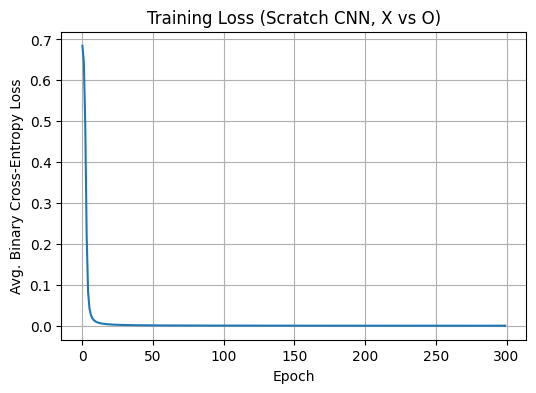

In [17]:
plt.figure(figsize=(6, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Avg. Binary Cross-Entropy Loss")
plt.title("Training Loss (Scratch CNN, X vs O)")
plt.grid(True)
plt.show()

## Sample test predictions

The first 8 test images, with the true label (T) and the predicted label (P) in each title.

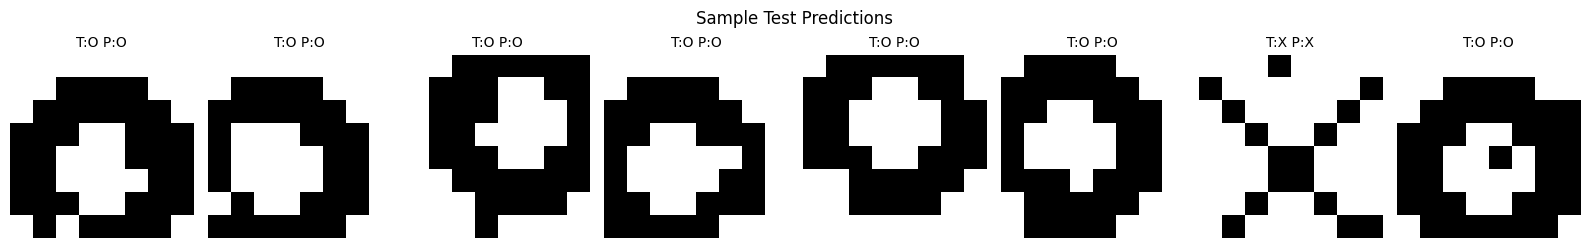

In [18]:
n_show = min(8, len(X_test))
fig, axes = plt.subplots(1, n_show, figsize=(2*n_show, 2.5))
for idx in range(n_show):
    ax = axes[idx]
    ax.imshow(X_test[idx, 0], cmap="gray_r")
    true_label = "X" if y_test[idx, 0] == 1 else "O"
    pred_label = "X" if predictions[idx, 0] == 1 else "O"
    ax.set_title(f"T:{true_label} P:{pred_label}", fontsize=10)
    ax.axis("off")
plt.suptitle("Sample Test Predictions")
plt.tight_layout()
plt.show()